In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import tensorflow as tf

d:\Damodarone\Python\venv\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
from keras.datasets import cifar10
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense
from keras.optimizers import Adam

In [5]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1727s 10us/step


Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)


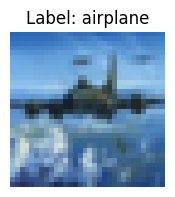

In [36]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print('Training images:', x_train.shape)
print('Training labels:', y_train.shape)
print('Test images:', x_test.shape)
print('Test labels:', y_test.shape)

plt.figure(figsize=(2,3))
idx = 1205
plt.imshow(x_train[idx], interpolation='nearest')
plt.title(f'Label: {class_names[int(y_train[idx])]}')
plt.axis('off')

plt.show()

In [23]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [24]:
model = Sequential([
    Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history = model.fit(
    x_train, y_train,
    epochs=2,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/2
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3238 - loss: 1.8966 - val_accuracy: 0.3701 - val_loss: 1.7681
Epoch 2/2
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3806 - loss: 1.7393 - val_accuracy: 0.3764 - val_loss: 1.7536


In [26]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print('Test Loss:', test_loss)
print('Test Accuracy:', test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3764 - loss: 1.7536
Test Loss: 1.7536427974700928
Test Accuracy: 0.3763999938964844


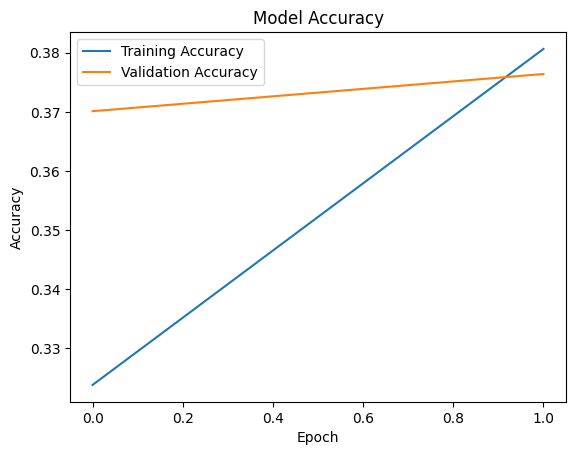

In [27]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

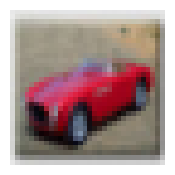

The image is classified as automobile
Actual class is automobile


In [35]:
n = int(input("Enter any index: "))

plt.figure(figsize=(2,3))
plt.imshow(x_test[n])
plt.axis('off')
plt.show()

prediction = model.predict(x_test[n:n + 1], verbose=0)

predicted_class = int(np.argmax(prediction[0]))

print('The image is classified as', class_names[predicted_class])
print('Actual class is', class_names[y_test[n]])